# Part 2: Centrality Analysis and Algorithm Validation

This notebook identifies important actors in Zachary's Karate Club network using degree, closeness, betweenness, eigenvector centrality, and PageRank. It also validates transparent from-scratch implementations against NetworkX.

**Research question:** Which members are influential, and how does the answer change when influence means connections, reach, brokerage, prestige, or random-walk visibility?

## Metric guide

| Metric | What it measures | Social interpretation |
| --- | --- | --- |
| Degree | Number of direct connections | Hub / highly connected member |
| Closeness | Average shortest-path distance | Efficient broadcaster |
| Betweenness | Share of shortest paths passing through a node | Broker or gatekeeper |
| Eigenvector | Connections to influential nodes | Prestigious / well-connected member |
| PageRank | Random-walk importance with damping | Visibility from important neighbours |

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

# Make the repository root importable whether Jupyter starts in the root or notebooks/.
PROJECT_ROOT = next(
    candidate for candidate in [Path.cwd(), *Path.cwd().parents]
    if (candidate / 'src').is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.centrality_algorithms import (
    compute_centralities,
    validate_manual_implementations,
)

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.float_format', '{:.4f}'.format)

## 1. Load the network

Zachary's Karate Club is a classic undirected social network with 34 members and 78 friendships. The fixed layout below makes the five visualisations directly comparable.

Nodes: 34 | Edges: 78 | Density: 0.139


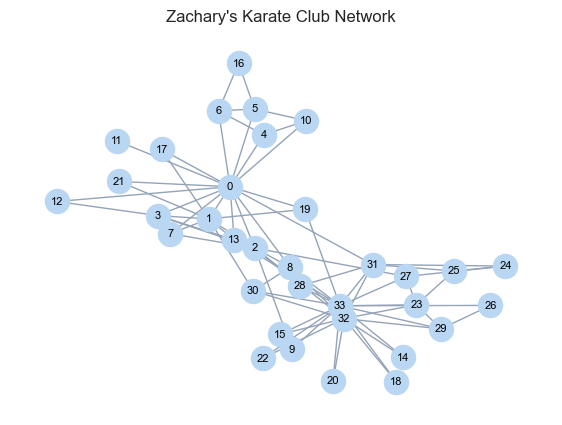

In [2]:
G = nx.karate_club_graph()
position = nx.spring_layout(G, seed=42)
print(f'Nodes: {G.number_of_nodes()} | Edges: {G.number_of_edges()} | Density: {nx.density(G):.3f}')

fig, ax = plt.subplots(figsize=(7, 5))
nx.draw_networkx(G, pos=position, ax=ax, node_size=300, node_color='#b9d6f2',
                 edge_color='#94a3b8', font_size=8, with_labels=True)
ax.set_title("Zachary's Karate Club Network")
ax.set_axis_off()
plt.show()

## 2. Calculate all five metrics

The reusable `compute_centralities` function uses NetworkX's tested implementations. All calculations are unweighted, so scores represent network structure rather than interaction frequency.

In [3]:
scores = compute_centralities(G)
centrality_df = pd.DataFrame(scores)
centrality_df.index.name = 'node'
centrality_df.head()

,degree,closeness,betweenness,eigenvector,pagerank
node,,,,,
0,0.4848,0.5690,0.4376,0.3555,0.0970
1,0.2727,0.4853,0.0539,0.2660,0.0529
2,0.3030,0.5593,0.1437,0.3172,0.0571
3,0.1818,0.4648,0.0119,0.2112,0.0359
4,0.0909,0.3793,0.0006,0.0760,0.0220


In [4]:
top_five = pd.DataFrame({
    metric: centrality_df[metric].nlargest(5).index.to_list()
    for metric in centrality_df.columns
}, index=[f'Rank {rank}' for rank in range(1, 6)])
top_five

,degree,closeness,betweenness,eigenvector,pagerank
Rank 1,33,0,0,33,33
Rank 2,0,2,33,0,0
Rank 3,32,33,32,2,32
Rank 4,2,31,2,32,2
Rank 5,1,8,31,1,1


## 3. Visual comparison

Node size and colour both increase with a node's score. Keeping the layout unchanged isolates what each centrality definition highlights.

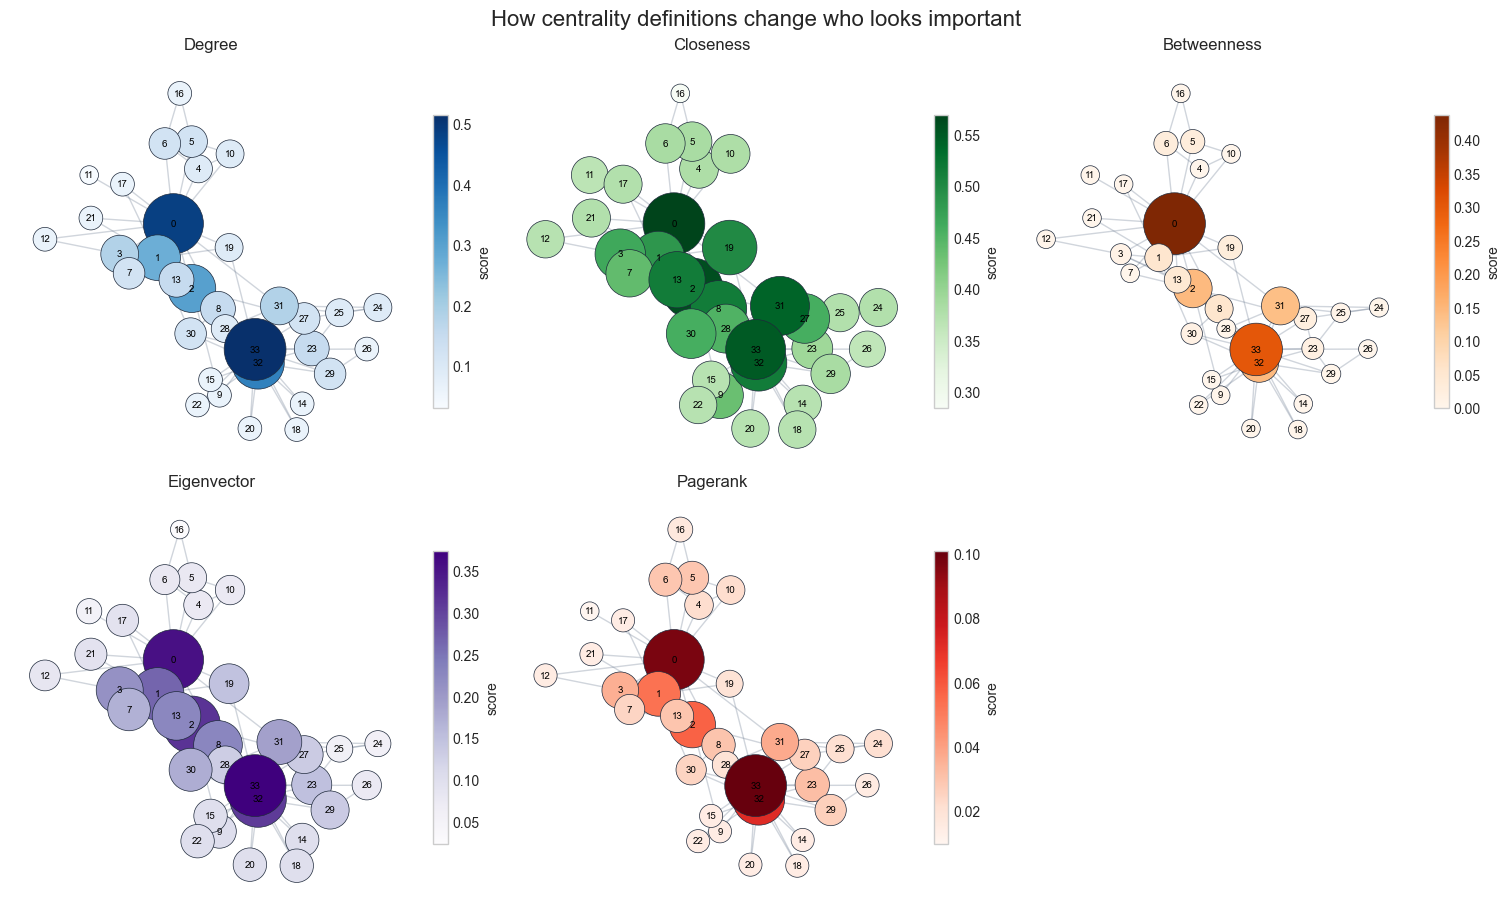

In [5]:
colormaps = {
    'degree': 'Blues', 'closeness': 'Greens', 'betweenness': 'Oranges',
    'eigenvector': 'Purples', 'pagerank': 'Reds',
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for axis, metric in zip(axes.flat, centrality_df.columns):
    values = centrality_df.loc[list(G.nodes()), metric]
    scaled_sizes = 180 + 1800 * (values - values.min()) / (values.max() - values.min() + 1e-12)
    nx.draw_networkx_edges(G, position, ax=axis, alpha=0.30, edge_color='#64748b')
    nodes = nx.draw_networkx_nodes(
        G, position, ax=axis, node_size=scaled_sizes, node_color=values,
        cmap=colormaps[metric], edgecolors='#1e293b', linewidths=0.5
    )
    nx.draw_networkx_labels(G, position, ax=axis, font_size=7)
    fig.colorbar(nodes, ax=axis, shrink=0.72, label='score')
    axis.set_title(metric.replace('_', ' ').title())
    axis.set_axis_off()
axes.flat[-1].set_axis_off()
fig.suptitle('How centrality definitions change who looks important', fontsize=16)
plt.show()

## 4. Do the metrics agree?

Spearman correlation compares ranking patterns without assuming that score scales are comparable. Values near 1 indicate similar rankings; values near 0 identify metrics that capture different social roles.

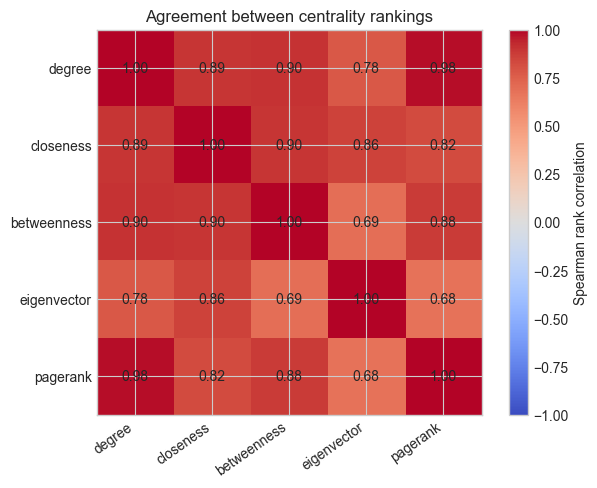

,degree,closeness,betweenness,eigenvector,pagerank
degree,1.0000,0.8950,0.9050,0.7770,0.9790
closeness,0.8950,1.0000,0.8980,0.8560,0.8250
betweenness,0.9050,0.8980,1.0000,0.6940,0.8790
eigenvector,0.7770,0.8560,0.6940,1.0000,0.6760
pagerank,0.9790,0.8250,0.8790,0.6760,1.0000


In [6]:
rank_correlation = centrality_df.corr(method='spearman')
fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(rank_correlation, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(rank_correlation.columns)), rank_correlation.columns, rotation=35, ha='right')
ax.set_yticks(range(len(rank_correlation.index)), rank_correlation.index)
for row in range(len(rank_correlation.index)):
    for column in range(len(rank_correlation.columns)):
        ax.text(column, row, f'{rank_correlation.iloc[row, column]:.2f}', ha='center', va='center')
fig.colorbar(image, ax=ax, label='Spearman rank correlation')
ax.set_title('Agreement between centrality rankings')
plt.show()
rank_correlation.round(3)

## 5. Validate the manual algorithms

For algorithmic transparency, the project also implements BFS-based closeness, Brandes betweenness, power-iteration eigenvector centrality, and PageRank directly in `src/centrality_algorithms.py`. The table reports each maximum absolute difference from NetworkX. A successful match shows that the implementation and normalisation are correct for this graph.

In [7]:
validation_df = pd.DataFrame(validate_manual_implementations(G)).T
validation_df

,max_abs_difference,match
degree,0.0000,True
closeness,0.0000,True
betweenness,0.0000,True
eigenvector,0.0000,True
pagerank,0.0000,True


## 6. Interpretation

- Compare the leaders in the top-five table rather than treating one score as universally best.
- In this network, a high-degree member is a local hub, while a high-betweenness member can control communication between otherwise distant parts of the club.
- Eigenvector centrality and PageRank favour members connected to other important members, so they can differ from simple degree.
- These measures describe topology, not leadership quality or causality; the result should be interpreted alongside the real social context.

## 7. Save results for the rest of the project

Part 3 can reuse this CSV for community and robustness analysis without recalculating the metrics.

In [8]:
output_path = PROJECT_ROOT / 'results' / 'tables' / 'centrality_scores.csv'
output_path.parent.mkdir(parents=True, exist_ok=True)
centrality_df.sort_values('degree', ascending=False).to_csv(output_path)
print(f'Saved {output_path.relative_to(PROJECT_ROOT)}')

Saved results\tables\centrality_scores.csv
